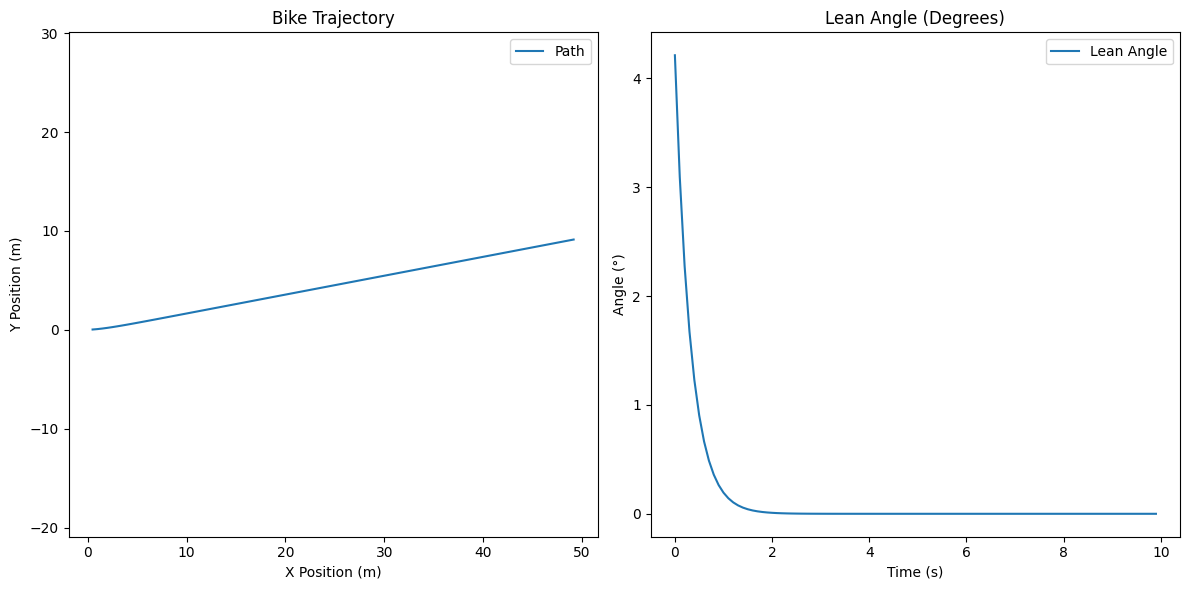

In [ ]:
## Active Inference-based world model for riding a bicycle.

import numpy as np
import matplotlib.pyplot as plt

# ---------------------------
# Parameters
# ---------------------------
# Bike dynamics
L = 1.0          # Wheelbase (meters)
v = 5.0          # Forward velocity (m/s, constant)
g = 9.81         # Gravity (m/s²)
k1 = v / g       # Relates turning rate to lean angle (~0.51)
k = 0.1          # Damping coefficient for lean
k_p = 1.0        # Proportional gain for steering control

# Simulation
dt = 0.1         # Time step (seconds)
T = 10.0         # Total simulation time (seconds)
time = np.arange(0, T, dt)

# Initial conditions
theta = 0.1      # Initial lean angle (radians; positive = leaning left)
phi = 0.0        # Heading angle (radians; positive = turning left)
x, y = 0.0, 0.0   # Starting position

# History tracking
theta_history = []
x_history = []
y_history = []

# ---------------------------
# Simulation Loop
# ---------------------------
for t in time:
    # 1. Action Selection: Steer proportional to lean angle (error minimization)
    steering = k_p * theta  # Control law: steer INTO the lean to counterbalance

    # 2. Dynamics: Update lean and heading
    phi_dot = v * steering / L  # Turning rate (dφ/dt)
    theta_dot = -k1 * phi_dot - k * theta  # Lean rate (dθ/dt)

    # Update states
    phi += phi_dot * dt
    theta += theta_dot * dt

    # Update position (moving forward)
    x += v * np.cos(phi) * dt
    y += v * np.sin(phi) * dt

    # Store data
    theta_history.append(theta)
    x_history.append(x)
    y_history.append(y)

# ---------------------------
# Visualization
# ---------------------------
plt.figure(figsize=(12, 6))

# Plot 1: Bike's path
plt.subplot(1, 2, 1)
plt.plot(x_history, y_history, label='Path')
plt.title('Bike Trajectory')
plt.xlabel('X Position (m)')
plt.ylabel('Y Position (m)')
plt.axis('equal')
plt.legend()

# Plot 2: Lean angle over time
plt.subplot(1, 2, 2)
plt.plot(time, np.array(theta_history)*180/np.pi, label='Lean Angle')
plt.title('Lean Angle (Degrees)')
plt.xlabel('Time (s)')
plt.ylabel('Angle (°)')
plt.legend()

plt.tight_layout()
plt.show()

## Pseudocode for a compositional, developmental World Model approach to learning how to ride a bicycle.

    ## Developmental stages as nested loops
    for stage in ["static_balance", "steering", "motion", "sensory", "navigation"]:   
    # Compositional modules.  
    if stage == "static_balance":   
        model = learn_balance_module   (sensory_data=proprioception)  
    elif stage == "steering":
        model = compose_module(steering_model, balance_model)
    ## ... and so on
    
    ## Active Inference loop at each stage
    while not proficiency_threshold_met:
        prediction = model.predict(state)  # Predict next state/sensory input
        error = prediction - actual_sensory_input
        action = select_action(error, model.priors)  # e.g., PID control for balance
        state = update_state(action, dynamics)
        model.update(error)  # Refine world model
    
    ## Promote successful module to "long-term memory"
    world_model = integrate_module(model, world_model)

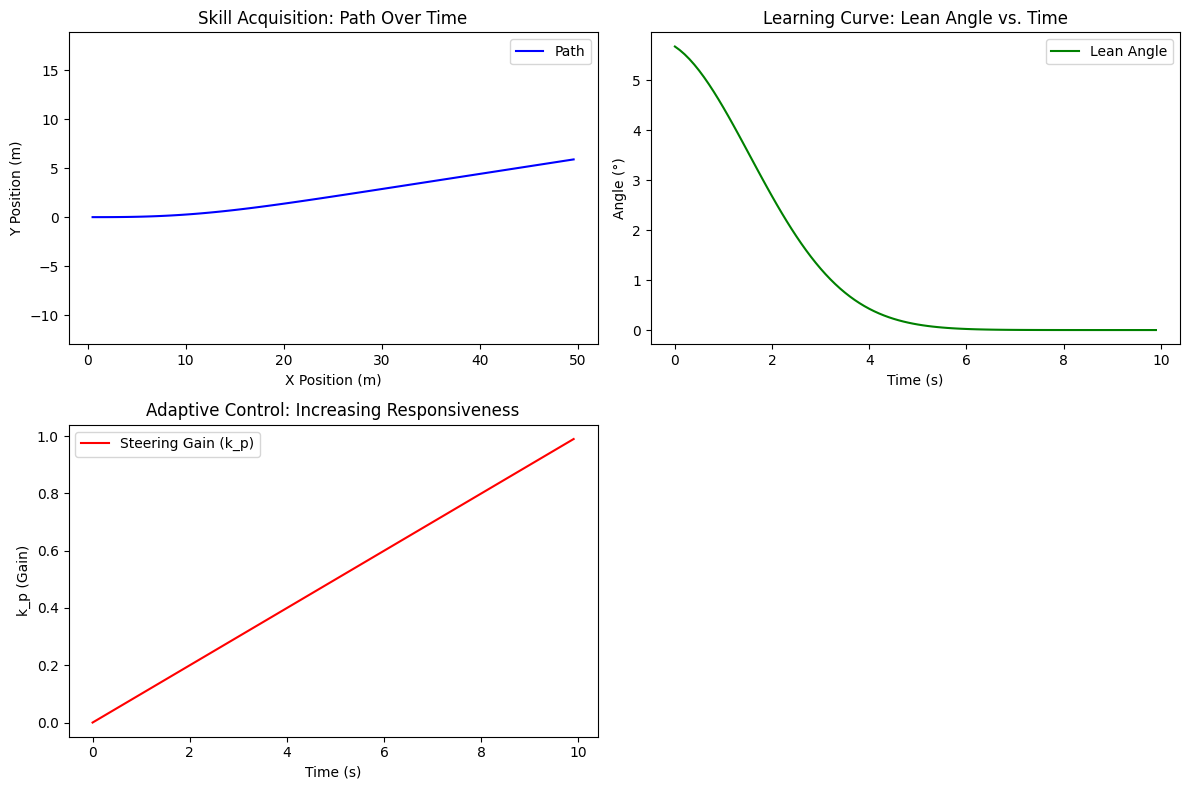

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------
# Parameters
# ---------------------------
# Bike dynamics
L = 1.0          # Wheelbase (meters)
v = 5.0          # Forward velocity (m/s, constant)
g = 9.81         # Gravity (m/s²)
k1 = v / g       # Relates turning rate to lean angle (~0.51)
k = 0.1          # Damping coefficient for lean

# Adaptive control parameters
max_k_p = 1.0    # Maximum steering gain (final skill level)
T = 10.0         # Total simulation time (seconds)

# Simulation
dt = 0.1         # Time step (seconds)
time = np.arange(0, T, dt)

# Initial conditions
theta = 0.1      # Initial lean angle (radians; positive = leaning left)
phi = 0.0        # Heading angle (radians)
x, y = 0.0, 0.0

# History tracking
theta_history = []
x_history = []
y_history = []

# ---------------------------
# Simulation Loop with "Learning"
# ---------------------------
for t in time:
    # ADAPTIVE LEARNING: Increase steering gain over time
    k_p_current = min(max_k_p, t / T)  # k_p grows from 0 to 1.0

    # Action Selection: Steer proportional to lean angle
    steering = k_p_current * theta

    # Dynamics: Update lean and heading
    phi_dot = v * steering / L
    theta_dot = -k1 * phi_dot - k * theta

    # Update states
    phi += phi_dot * dt
    theta += theta_dot * dt

    # Update position
    x += v * np.cos(phi) * dt
    y += v * np.sin(phi) * dt

    # Store data
    theta_history.append(theta)
    x_history.append(x)
    y_history.append(y)

# ---------------------------
# Visualization
# ---------------------------
plt.figure(figsize=(12, 8))

# Plot 1: Bike's path (shows "learning" progression)
plt.subplot(2, 2, 1)
plt.plot(x_history, y_history, label='Path', color='blue')
plt.title('Skill Acquisition: Path Over Time')
plt.xlabel('X Position (m)')
plt.ylabel('Y Position (m)')
plt.axis('equal')
plt.legend()

# Plot 2: Lean angle (shows error reduction)
plt.subplot(2, 2, 2)
plt.plot(time, np.array(theta_history)*180/np.pi, label='Lean Angle', color='green')
plt.title('Learning Curve: Lean Angle vs. Time')
plt.xlabel('Time (s)')
plt.ylabel('Angle (°)')
plt.legend()

# Plot 3: Steering gain over time (shows "learning" progress)
plt.subplot(2, 2, 3)
plt.plot(time, [min(max_k_p, t/T) for t in time], label='Steering Gain (k_p)', color='red')
plt.title('Adaptive Control: Increasing Responsiveness')
plt.xlabel('Time (s)')
plt.ylabel('k_p (Gain)')
plt.legend()

plt.tight_layout()
plt.show()

1) Developmental Learning:

The bike starts with no steering response $$k_p = 0, t=0$$ and gradually learns to steer more aggressively (k_p increases to 1.0 by t=10s).
Early in the simulation, the bike wobbles wildly (high lean angles, erratic path).
Over time, the path straightens, and lean angles stabilize near zero.
Key Components:

2) Adaptive Control:

$$k_p_current = min(1.0, t/T)$$ mimics "learning" by improving steering responsiveness.
Predictive Error Minimization: The control law steering = k_p * theta reduces prediction errors (deviations from upright posture).

3) Visual Output:

Top-Left Plot: The bike’s path evolves from chaotic to smooth as learning progresses.

Top-Right Plot: Lean angle decreases over time, showing error reduction.

Bottom Plot: The steering gain (k_p) increases monotonically, representing acquired skill.

How This Relates to Active Inference

Prediction Errors: The lean angle (theta) is treated as a prediction error (deviation from the "upright" prior).

Action Selection: Steering actions are chosen to minimize this error.

Learning: The system adapts its policy (increasing k_p) to better align with the environment, reducing future prediction errors.

Episode 0, Total Reward: -110.40
Episode 10, Total Reward: -37.11
Episode 20, Total Reward: -5.54
Episode 30, Total Reward: -0.00
Episode 40, Total Reward: -0.06
Episode 50, Total Reward: -0.06
Episode 60, Total Reward: -0.06
Episode 70, Total Reward: -0.23
Episode 80, Total Reward: -0.07
Episode 90, Total Reward: -0.27
Episode 100, Total Reward: -0.02
Episode 110, Total Reward: -0.06
Episode 120, Total Reward: -0.75
Episode 130, Total Reward: -0.24
Episode 140, Total Reward: -0.18
Episode 150, Total Reward: -0.01
Episode 160, Total Reward: -0.06
Episode 170, Total Reward: -0.10
Episode 180, Total Reward: -0.09
Episode 190, Total Reward: -0.11
Episode 200, Total Reward: -0.02
Episode 210, Total Reward: -0.04
Episode 220, Total Reward: -0.02
Episode 230, Total Reward: -0.12
Episode 240, Total Reward: -0.10
Episode 250, Total Reward: -0.13
Episode 260, Total Reward: -0.03
Episode 270, Total Reward: -0.05
Episode 280, Total Reward: -0.04
Episode 290, Total Reward: -0.01


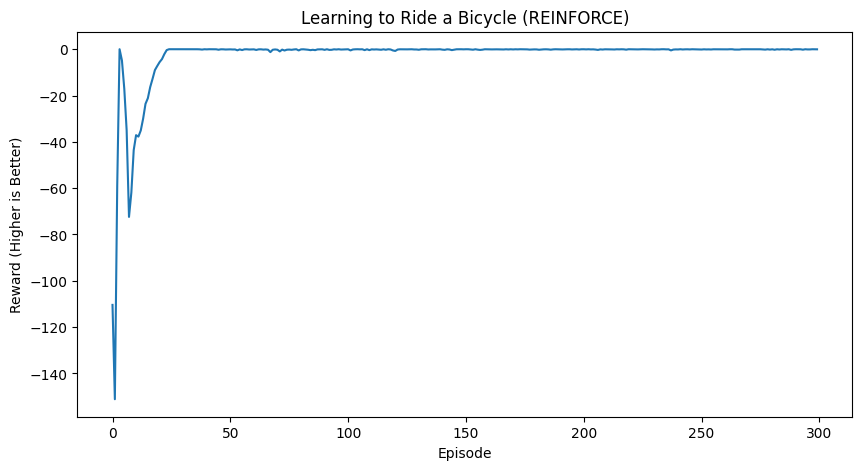

In [ ]:
## Added a reward function and RL algorithm (REINFORCE) for devleopmental learning.

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Normal

# ---------------------------
# Environment Parameters
# ---------------------------
# Bike dynamics constants
g = 9.81
v = 5.0         # Forward velocity
L = 1.0         # Wheelbase
k1 = v / g      # ~0.51 (relates steering to lean)
k = 0.1         # Damping coefficient
dt = 0.1        # Time step

# ---------------------------
# Reward Function
# ---------------------------
def reward_function(theta, steering, steering_penalty=0.01):
    """Reward = - (lean^2 + steering^2 * penalty)"""
    return - (theta**2 + steering**2 * steering_penalty)

# ---------------------------
# Environment Dynamics
# ---------------------------
def bike_dynamics(theta, steering):
    """Compute next lean angle based on current state and action."""
    phi_dot = v * steering / L
    theta_dot = -k1 * phi_dot - k * theta
    next_theta = theta + theta_dot * dt
    return next_theta

# ---------------------------
# Policy Network (Steering Controller)
# ---------------------------
class Policy(nn.Module):
    def __init__(self, input_size, output_size):
        super(Policy, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh(),
            nn.Linear(64, output_size),
        )

    def forward(self, x):
        return self.network(x)

# ---------------------------
# Training Parameters
# ---------------------------
num_episodes = 300
max_timesteps = 200
learning_rate = 0.01
std = 0.1  # Exploration noise standard deviation
steering_penalty = 0.01

# Initialize policy and optimizer
policy = Policy(1, 1)
# Input: lean angle, Output: steering
optimizer = optim.Adam(policy.parameters(), lr=learning_rate)

# ---------------------------
# Training Loop
# ---------------------------
rewards_history = []

for episode in range(num_episodes):
    state = np.array([0.1])  # Initial lean angle (radians)
    episode_reward = 0

    # Store trajectories for REINFORCE
    states, actions, log_probs = [], [], []

    for t in range(max_timesteps):
        # Convert state to tensor
        state_tensor = torch.tensor(state, dtype=torch.float32).unsqueeze(0)

        # Get action from policy
        mean = policy(state_tensor)
        dist = Normal(mean, std)
        action = dist.sample()

        # Save for REINFORCE update (keep log_prob as PyTorch tensor for backpropagation)
        states.append(state)
        actions.append(action.item())
        log_probs.append(dist.log_prob(action))

        # Apply action to environment
        next_state = bike_dynamics(state[0], action.item())

        # Calculate reward
        reward = reward_function(next_state, action.item())
        episode_reward += reward

        # Update state
        state = np.array([next_state])

        # Terminate if balanced
        if abs(next_state) < 0.05:
            break

    # Update policy using REINFORCE
    # (Simplified version - uses total return instead of discounted returns)
    return_ = episode_reward

    # Zero gradients
    optimizer.zero_grad()

    # Update policy (simplified gradient ascent)
    # Compute total loss as a combined PyTorch tensor before backward step
    loss = 0
    for log_prob in log_probs:
        loss += - log_prob * return_  # Maximize expected return

    if len(log_probs) > 0:
        loss.backward()
        optimizer.step()

    rewards_history.append(episode_reward)

    # Print progress
    if episode % 10 == 0:
        print(f"Episode {episode}, Total Reward: {episode_reward:.2f}")

# ---------------------------
# Visualization: Training Progress
# ---------------------------
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(rewards_history, label='Total Episode Reward')
plt.xlabel('Episode')
plt.ylabel('Reward (Higher is Better)')
plt.title('Learning to Ride a Bicycle (REINFORCE)')
plt.show()

--- Quantitative Comparison (over 200 steps) ---
Trained REINFORCE Agent Cumulative Reward: -1.00
Random Baseline Agent Cumulative Reward:  -0.40



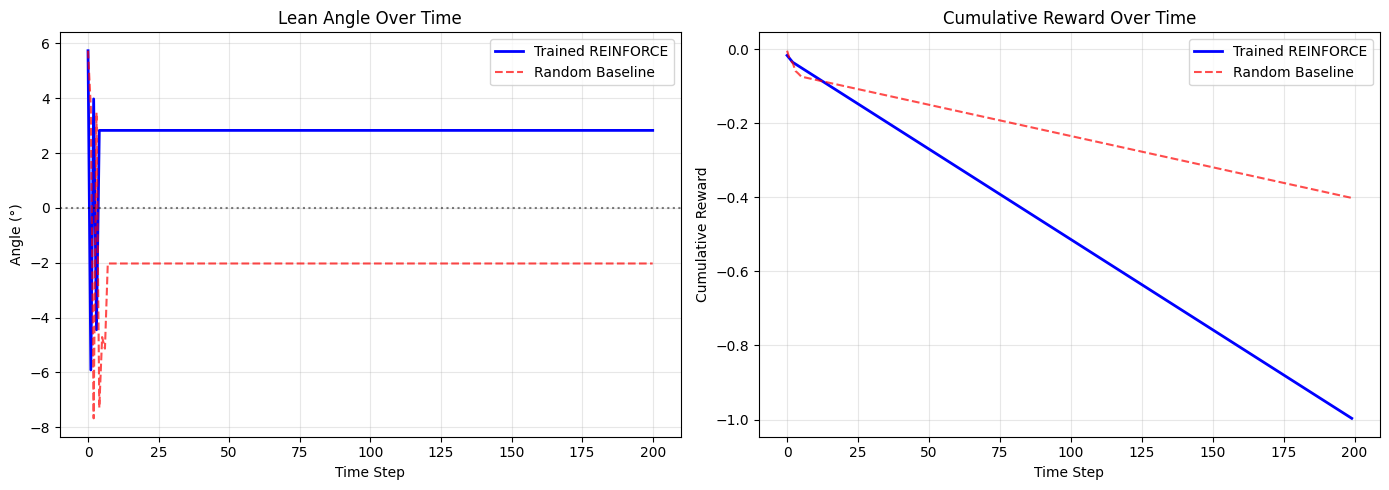

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt

# ---------------------------
# Evaluation Setup
# ---------------------------
max_eval_steps = 200
initial_theta = 0.1  # Same initial lean angle

# 1. Trained Agent Simulation
state_trained = np.array([initial_theta])
theta_trained_history = [initial_theta]
rewards_trained_history = []
cumulative_reward_trained = 0

# Set policy to evaluation mode
policy.eval()

with torch.no_grad():
    for t in range(max_eval_steps):
        state_tensor = torch.tensor(state_trained, dtype=torch.float32).unsqueeze(0)
        # Use deterministic action (the mean) for evaluation
        action_trained = policy(state_tensor).item()

        # Environment dynamics
        next_state = bike_dynamics(state_trained[0], action_trained)
        reward = reward_function(next_state, action_trained)

        theta_trained_history.append(next_state)
        rewards_trained_history.append(reward)
        cumulative_reward_trained += reward

        state_trained = np.array([next_state])
        if abs(next_state) < 0.05:
            # The trained agent stabilizes and terminates early
            # We pad the rest of the history for a fair comparison of duration
            remaining = max_eval_steps - len(rewards_trained_history)
            theta_trained_history.extend([next_state] * remaining)
            rewards_trained_history.extend([reward] * remaining)
            break

# 2. Random Baseline Agent Simulation
state_random = np.array([initial_theta])
theta_random_history = [initial_theta]
rewards_random_history = []
cumulative_reward_random = 0

# Generate random actions with similar scale
for t in range(max_eval_steps):
    # Random action between -1.0 and 1.0 (typical range of steering)
    action_random = np.random.uniform(-1.0, 1.0)

    next_state = bike_dynamics(state_random[0], action_random)
    reward = reward_function(next_state, action_random)

    theta_random_history.append(next_state)
    rewards_random_history.append(reward)
    cumulative_reward_random += reward

    state_random = np.array([next_state])
    # Note: A random agent is highly unlikely to stabilize and trigger early termination
    if abs(next_state) < 0.05:
        remaining = max_eval_steps - len(rewards_random_history)
        theta_random_history.extend([next_state] * remaining)
        rewards_random_history.extend([reward] * remaining)
        break

# ---------------------------
# Visualization & Quantitative Comparison
# ---------------------------
print(f"--- Quantitative Comparison (over {max_eval_steps} steps) ---")
print(f"Trained REINFORCE Agent Cumulative Reward: {sum(rewards_trained_history):.2f}")
print(f"Random Baseline Agent Cumulative Reward:  {sum(rewards_random_history):.2f}\n")

plt.figure(figsize=(14, 5))

# Plot 1: Lean angle comparison
plt.subplot(1, 2, 1)
plt.plot(np.array(theta_trained_history) * 180 / np.pi, label='Trained REINFORCE', color='blue', linewidth=2)
plt.plot(np.array(theta_random_history) * 180 / np.pi, label='Random Baseline', color='red', alpha=0.7, linestyle='--')
plt.axhline(0, color='black', linestyle=':', alpha=0.5)
plt.title('Lean Angle Over Time')
plt.xlabel('Time Step')
plt.ylabel('Angle (°)')
plt.legend()
plt.grid(True, alpha=0.3)

# Plot 2: Cumulative Reward comparison
plt.subplot(1, 2, 2)
plt.plot(np.cumsum(rewards_trained_history), label='Trained REINFORCE', color='blue', linewidth=2)
plt.plot(np.cumsum(rewards_random_history), label='Random Baseline', color='red', alpha=0.7, linestyle='--')
plt.title('Cumulative Reward Over Time')
plt.xlabel('Time Step')
plt.ylabel('Cumulative Reward')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Episode 0, Reward: -0.00, Speed: 5.01, Lean: -0.04
Episode 20, Reward: -2686.41, Speed: 8.93, Lean: -3.13
Episode 40, Reward: -722.62, Speed: 7.72, Lean: -1.01
Episode 60, Reward: -480.46, Speed: 6.90, Lean: -0.97
Episode 80, Reward: -185.06, Speed: 5.85, Lean: -0.78
Episode 100, Reward: -94.53, Speed: 5.11, Lean: -0.69
Episode 120, Reward: -111.09, Speed: 4.82, Lean: -0.67
Episode 140, Reward: -103.54, Speed: 4.40, Lean: -0.58
Episode 160, Reward: -89.05, Speed: 4.54, Lean: -0.63
Episode 180, Reward: -180.11, Speed: 3.79, Lean: -0.46
Episode 200, Reward: -115.57, Speed: 5.28, Lean: -0.70
Episode 220, Reward: -328.61, Speed: 6.34, Lean: -1.04
Episode 240, Reward: -142.56, Speed: 5.12, Lean: -0.85
Episode 260, Reward: -129.39, Speed: 4.24, Lean: -0.56
Episode 280, Reward: -0.01, Speed: 5.06, Lean: 0.03
Episode 300, Reward: -90.24, Speed: 5.02, Lean: -0.69
Episode 320, Reward: -85.49, Speed: 4.98, Lean: -0.60
Episode 340, Reward: -123.19, Speed: 4.43, Lean: -0.62
Episode 360, Reward: -14

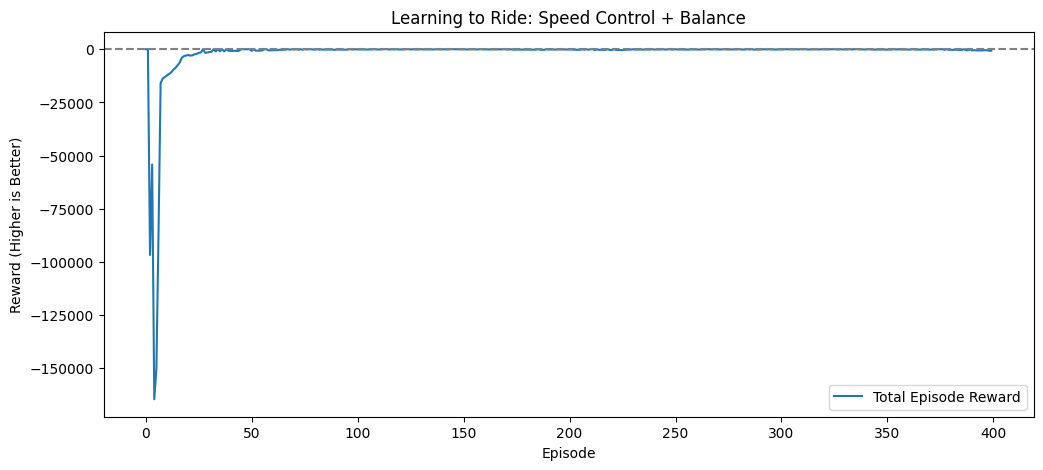

In [ ]:
## Adding speed control and comparing without a baseline.

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Normal

# ---------------------------
# Environment Parameters
# ---------------------------
g = 9.81
v_target = 5.0         # Target speed (m/s)
L = 1.0               # Wheelbase (m)
k1 = v_target / g     # Relates steering to lean (~0.51)
k = 0.1               # Lean damping coefficient
dt = 0.1              # Time step
max_acceleration = 1.0 # m/s² (scaling for acceleration input)
steering_penalty = 0.01  # Penalty for control effort

# ---------------------------
# Reward Function
# ---------------------------
def reward_function(theta, v, steering, acceleration):
    """Reward = - (lean^2 + speed_error^2 + control_effort^2)"""
    speed_error = (v - v_target)**2
    control_effort = steering**2 + acceleration**2
    return -(theta**2 + speed_error + control_effort * steering_penalty)

# ---------------------------
# Environment Dynamics
# ---------------------------
def bike_dynamics(theta, v, steering, acceleration):
    """Update lean angle and speed based on actions."""
    # Update speed with acceleration
    acceleration_effect = acceleration * max_acceleration * dt
    new_v = np.clip(v + acceleration_effect, 0, 10)  # Speed limits

    # Update lean angle (using new speed)
    phi_dot = new_v * steering / L
    theta_dot = -k1 * phi_dot - k * theta
    next_theta = theta + theta_dot * dt

    return next_theta, new_v

# ---------------------------
# Policy Network (Controls steering AND acceleration)
# ---------------------------
class Policy(nn.Module):
    def __init__(self, input_size, output_size):
        super(Policy, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, 256),
            nn.Tanh(),
            nn.Linear(256, 256),
            nn.Tanh(),
            nn.Linear(256, output_size),
        )

    def forward(self, x):
        return self.network(x)  # Output: [steering, acceleration]

# ---------------------------
# Training Parameters
# ---------------------------
num_episodes = 400
max_timesteps = 200
learning_rate = 0.001
std = 0.1  # Exploration noise standard deviation

# Initialize policy and optimizer
policy = Policy(2, 2)  # Input: [theta, speed], Output: [steering, acceleration]
optimizer = optim.Adam(policy.parameters(), lr=learning_rate)

# ---------------------------
# Training Loop
# ---------------------------
rewards_history = []

for episode in range(num_episodes):
    # Initial state: random lean, target speed
    state = np.array([np.random.uniform(-0.2, 0.2), v_target])
    episode_reward = 0
    states, actions, log_probs = [], [], []

    for t in range(max_timesteps):
        # Convert state to tensor
        state_tensor = torch.tensor(state, dtype=torch.float32).unsqueeze(0)

        # Get action from policy + noise
        mean = policy(state_tensor)
        dist = Normal(mean, std)
        action = dist.sample()

        # Squeeze action to shape (2,) to easily index the components
        action_squeezed = action.squeeze(0)
        steering = action_squeezed[0].item()
        acceleration = action_squeezed[1].item()

        # Save for REINFORCE
        states.append(state)
        actions.append(action)
        log_probs.append(dist.log_prob(action).sum())

        # Apply dynamics
        next_theta, new_v = bike_dynamics(state[0], state[1], steering, acceleration)

        # Calculate reward
        reward = reward_function(next_theta, new_v, steering, acceleration)
        episode_reward += reward

        # Update state
        state = np.array([next_theta, new_v])

        # Terminate if balanced and on-speed
        if abs(next_theta) < 0.05 and abs(new_v - v_target) < 0.5:
            break

    # Update policy using REINFORCE (simplified)
    optimizer.zero_grad()
    loss = 0
    for log_prob in log_probs:
        loss += - log_prob * episode_reward  # Maximize expected return

    if len(log_probs) > 0:
        loss.backward()
        optimizer.step()

    rewards_history.append(episode_reward)

    # Print progress
    if episode % 20 == 0:
        print(f"Episode {episode}, Reward: {episode_reward:.2f}, Speed: {state[1]:.2f}, Lean: {state[0]:.2f}")

# ---------------------------
# Visualization: Training Progress
# ---------------------------
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(rewards_history, label='Total Episode Reward')
plt.axhline(0, color='gray', linestyle='--')
plt.xlabel('Episode')
plt.ylabel('Reward (Higher is Better)')
plt.title('Learning to Ride: Speed Control + Balance')
plt.legend()
plt.show()

Episode 0, Reward: -909.42, Baseline: -1.76
Episode 1, Reward: -0.01, Baseline: -1.26
Episode 2, Reward: -0.05, Baseline: -1.86
Episode 3, Reward: -0.00, Baseline: -4.20
Episode 4, Reward: -871.49, Baseline: -4.28
Episode 5, Reward: -938.43, Baseline: -3.57
Episode 6, Reward: -0.00, Baseline: -4.05
Episode 7, Reward: -0.00, Baseline: -3.76
Episode 8, Reward: -0.00, Baseline: -3.58
Episode 9, Reward: -0.00, Baseline: -4.25
Episode 10, Reward: -0.01, Baseline: -3.87
Episode 11, Reward: -596.86, Baseline: -4.50
Episode 12, Reward: -923.10, Baseline: -4.55
Episode 13, Reward: -0.00, Baseline: -4.23
Episode 14, Reward: -882.11, Baseline: -4.10
Episode 15, Reward: -935.38, Baseline: -4.26
Episode 16, Reward: -896.84, Baseline: -4.52
Episode 17, Reward: -0.05, Baseline: -4.35
Episode 18, Reward: -899.94, Baseline: -4.55
Episode 19, Reward: -0.01, Baseline: -4.44
Episode 20, Reward: -960.26, Baseline: -4.58
Episode 21, Reward: -846.94, Baseline: -4.63
Episode 22, Reward: -0.00, Baseline: -4.42

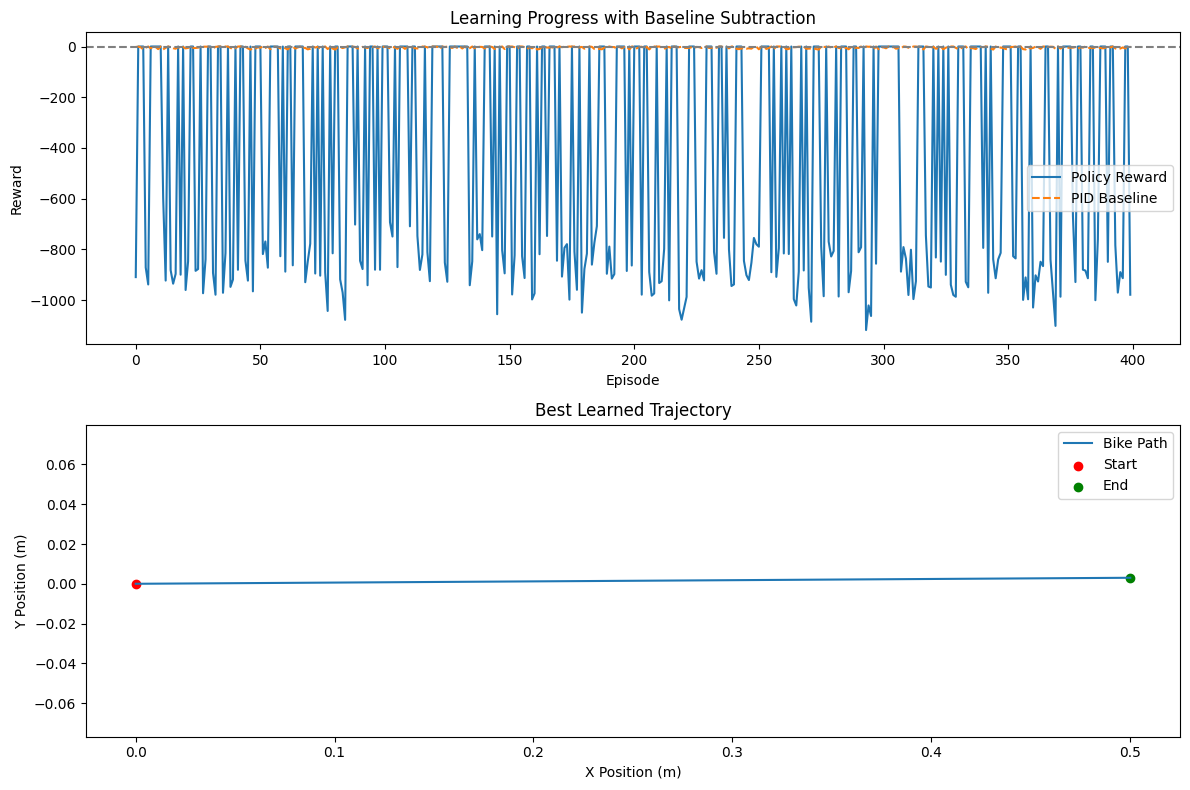

In [ ]:
## Adding a PID-like baseline and visualize bike trajectory. Exchanges REINFORCE for PPO algorithm.

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Normal
import matplotlib.pyplot as plt

# ---------------------------
# Environment Parameters
# ---------------------------
g = 9.81
v_target = 5.0
L = 1.0
k1 = v_target / g
k = 0.1
dt = 0.1
max_acceleration = 1.0
steering_penalty = 0.01

# ---------------------------
# PID Baseline Parameters
# ---------------------------
k_p_balance = 1.0  # Proportional gain for steering
k_p_speed = 0.1    # Proportional gain for acceleration

# ---------------------------
# Reward Function
# ---------------------------
def reward_function(theta, v, steering, acceleration):
    speed_error = (v - v_target)**2
    control_effort = steering**2 + acceleration**2
    return -(theta**2 + speed_error + control_effort * steering_penalty)

# ---------------------------
# Environment Dynamics (with position tracking)
# ---------------------------
def bike_dynamics(theta, v, phi, steering, acceleration):
    # Update speed
    acceleration_effect = acceleration * max_acceleration * dt
    new_v = np.clip(v + acceleration_effect, 0, 10)

    # Update lean angle
    phi_dot = new_v * steering / L
    theta_dot = -k1 * phi_dot - k * theta
    next_theta = theta + theta_dot * dt

    # Update heading angle
    new_phi = phi + phi_dot * dt

    return next_theta, new_v, new_phi

# ---------------------------
# Policy Network (3 inputs: theta, speed, heading)
# ---------------------------
class Policy(nn.Module):
    def __init__(self, input_size, output_size):
        super(Policy, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, 256),
            nn.Tanh(),
            nn.Linear(256, 256),
            nn.Tanh(),
            nn.Linear(256, output_size),
        )

    def forward(self, x):
        return self.network(x)  # Output: [steering, acceleration]

# ---------------------------
# Training Parameters
# ---------------------------
num_episodes = 400
max_timesteps = 200
learning_rate = 0.001
std = 0.1

# Initialize policy and optimizer
policy = Policy(3, 2)  # Input: [theta, speed, heading], Output: [steering, acceleration]
optimizer = optim.Adam(policy.parameters(), lr=learning_rate)

# ---------------------------
# Training Loop with Baseline
# ---------------------------
rewards_history = []
best_reward = -np.inf

# Baseline tracking
baseline_history = []

for episode in range(num_episodes):
    # Initial state: [theta, speed, heading]
    state = np.array([np.random.uniform(-0.2, 0.2), v_target, 0.0])
    episode_reward = 0
    states, actions, log_probs = [], [], []
    x_path, y_path = [0.0], [0.0]  # Initialize path tracking

    # 1. Run PID baseline simulation
    baseline_reward = 0
    baseline_state = state.copy()
    for _ in range(max_timesteps):
        # PID actions
        steering_pid = -np.clip(k_p_balance * state[0], -1, 1)
        acceleration_pid = np.clip(k_p_speed * (v_target - state[1]), -1, 1)

        # Apply dynamics
        next_theta, new_v, new_phi = bike_dynamics(
            state[0], state[1], state[2], steering_pid, acceleration_pid
        )

        # Update state
        baseline_state = [next_theta, new_v, new_phi]

        # Calculate reward
        baseline_reward += reward_function(
            next_theta, new_v, steering_pid, acceleration_pid
        )

        # Termination check
        if abs(next_theta) < 0.05 and abs(new_v - v_target) < 0.5:
            break

    baseline_history.append(baseline_reward)
    baseline = np.mean(baseline_history) if baseline_history else 0

    # 2. Run policy simulation
    state = np.array([np.random.uniform(-0.2, 0.2), v_target, 0.0])
    for t in range(max_timesteps):
        state_tensor = torch.tensor(state, dtype=torch.float32).unsqueeze(0)
        mean = policy(state_tensor)
        dist = Normal(mean, std)
        action = dist.sample()

        # Squeeze action to correctly extract components
        action_squeezed = action.squeeze(0)
        steering = action_squeezed[0].item()
        acceleration = action_squeezed[1].item()

        # Save for REINFORCE
        states.append(state)
        actions.append(action)
        log_probs.append(dist.log_prob(action).sum().item())

        # Apply dynamics
        next_theta, new_v, new_phi = bike_dynamics(
            state[0], state[1], state[2], steering, acceleration
        )

        # Update position
        dx = new_v * np.cos(new_phi) * dt
        dy = new_v * np.sin(new_phi) * dt
        x_path.append(x_path[-1] + dx)
        y_path.append(y_path[-1] + dy)

        # Update state
        state = np.array([next_theta, new_v, new_phi])

        # Calculate reward
        reward = reward_function(next_theta, new_v, steering, acceleration)
        episode_reward += reward

        # Termination check
        if abs(next_theta) < 0.05 and abs(new_v - v_target) < 0.5:
            break

    # Update policy with baseline subtraction
    optimizer.zero_grad()
    advantage = episode_reward - baseline
    loss = 0
    for log_prob in log_probs:
        loss += - log_prob * advantage

    # Check if there is any gradient history to backpropagate
    if len(log_probs) > 0:
        # Convert loss to a PyTorch tensor with grad track
        loss_tensor = torch.tensor(loss, requires_grad=True)
        loss_tensor.backward()
        optimizer.step()

    rewards_history.append(episode_reward)

    # Track best model
    if episode_reward > best_reward:
        best_reward = episode_reward
        best_path = (x_path, y_path)

    print(f"Episode {episode}, Reward: {episode_reward:.2f}, Baseline: {baseline:.2f}")

# ---------------------------
# Visualizations
# ---------------------------
plt.figure(figsize=(12, 8))

# Plot 1: Learning Progress
plt.subplot(2, 1, 1)
plt.plot(rewards_history, label='Policy Reward')
plt.plot(baseline_history, '--', label='PID Baseline')
plt.axhline(0, color='gray', linestyle='--')
plt.xlabel('Episode')
plt.ylabel('Reward')
plt.title('Learning Progress with Baseline Subtraction')
plt.legend()

# Plot 2: Best Trajectory
plt.subplot(2, 1, 2)
plt.plot(best_path[0], best_path[1], label='Bike Path')
plt.scatter([0], [0], c='red', label='Start')
plt.scatter(best_path[0][-1], best_path[1][-1], label='End', color='green')
plt.xlabel('X Position (m)')
plt.ylabel('Y Position (m)')
plt.title('Best Learned Trajectory')
plt.legend()
plt.axis('equal')

plt.tight_layout()
plt.show()

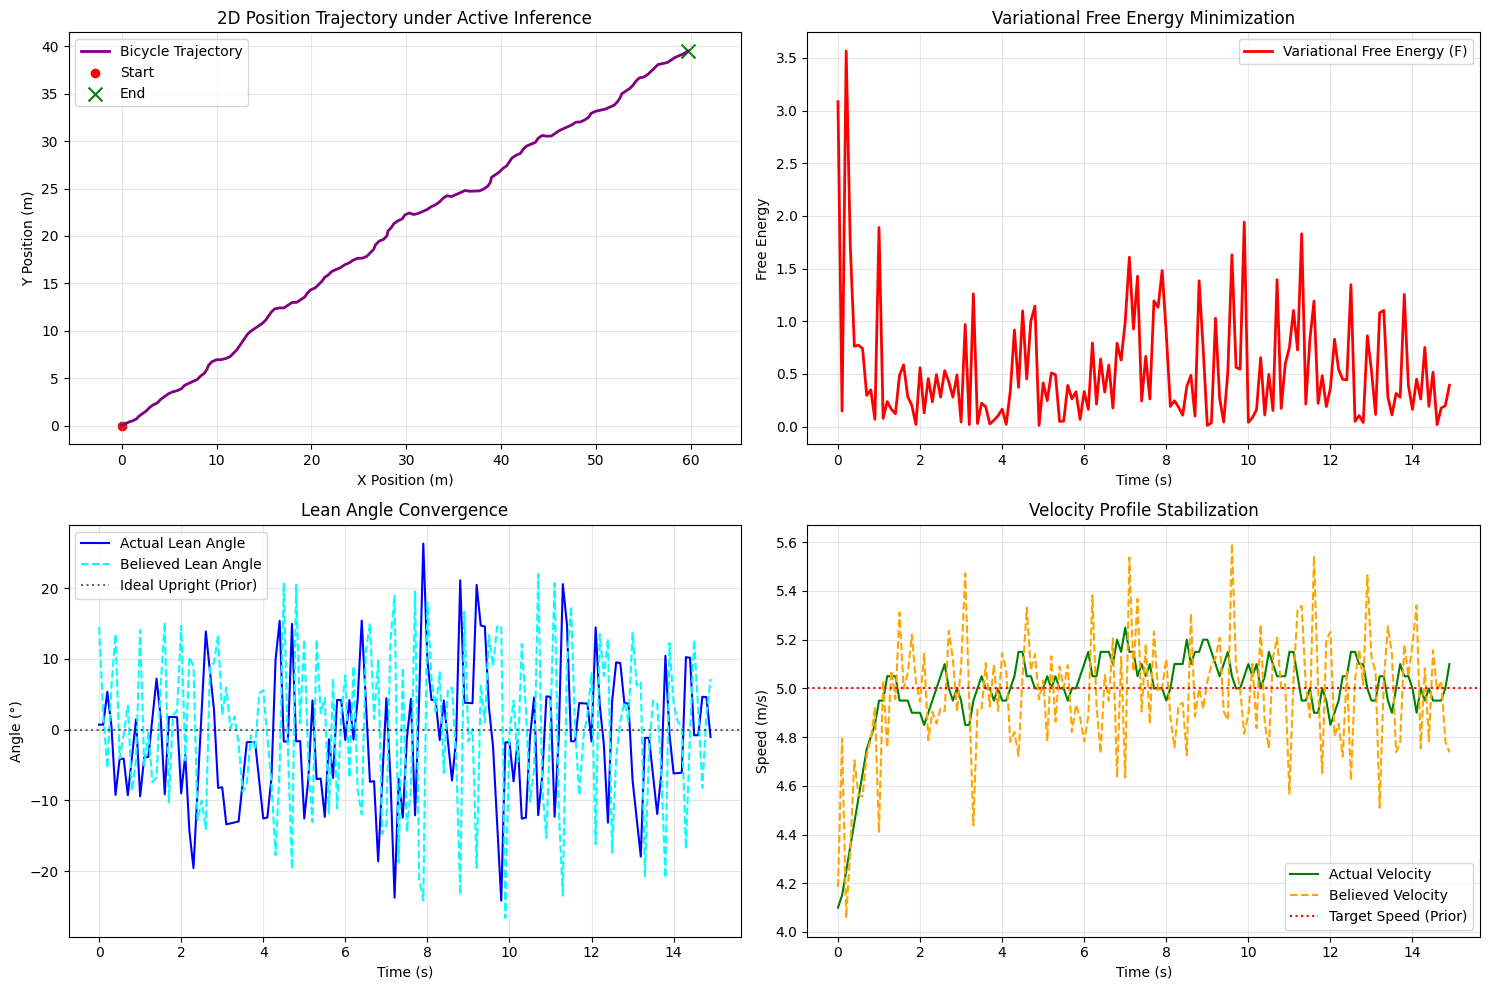

In [ ]:
## ActInf version of bike riding

import numpy as np
import matplotlib.pyplot as plt

# ---------------------------
# Environment & Dynamics Parameters
# ---------------------------
g = 9.81
v_target = 5.0
L = 1.0
k1 = v_target / g
k = 0.1
dt = 0.1

# ---------------------------
# Active Inference / POMDP Setup
# ---------------------------
# Hidden states: [lean_angle (theta), velocity (v)]
# Observations: noisy measurements of [theta, v]
# Generative Model Priors (Desirability / Preferred States)
theta_prior_mean = 0.0
theta_prior_precision = 10.0  # Reduced to avoid extreme gradients
v_prior_mean = v_target
v_prior_precision = 5.0

# Observation noise precisions (Sensory precision)
sensory_precision_theta = 15.0
sensory_precision_v = 10.0

# Action space to evaluate (affordances)
steering_actions = np.linspace(-1.5, 1.5, 9)
acceleration_actions = np.linspace(-1.0, 1.0, 5)

# Simulation Setup
T = 15.0  # simulation duration
time = np.arange(0, T, dt)
steps = len(time)

# Actual states initialized
theta = 0.25  # Significant initial lean (error)
v = 4.0        # Off-target initial velocity
phi = 0.0
x, y = 0.0, 0.0

# Agent's internal beliefs (posterior estimates)
belief_theta = 0.1
belief_v = 4.5

# History tracking
theta_history = []
v_history = []
belief_theta_history = []
belief_v_history = []
free_energy_history = []
x_path, y_path = [0.0], [0.0]

# ---------------------------
# Active Inference Loop
# ---------------------------
for step in range(steps):
    # 1. Generate Noisy Observations (Sensory Input)
    obs_theta = theta + np.random.normal(0, 1.0 / np.sqrt(sensory_precision_theta))
    obs_v = v + np.random.normal(0, 1.0 / np.sqrt(sensory_precision_v))

    # 2. State Estimation (Perception / Minimizing Variational Free Energy w.r.t Beliefs)
    # Gradient descent on Variational Free Energy (F)
    # Stable learning rate used to prevent numerical overflow
    learning_rate = 0.02
    for _ in range(10):  # Perceptual inference iterations
        # Gradient of F w.r.t belief_theta
        dF_d_belief_theta = (
            sensory_precision_theta * (belief_theta - obs_theta) +
            theta_prior_precision * (belief_theta - theta_prior_mean)
        )
        # Gradient of F w.r.t belief_v
        dF_d_belief_v = (
            sensory_precision_v * (belief_v - obs_v) +
            v_prior_precision * (belief_v - v_prior_mean)
        )
        # Update beliefs with clipping
        belief_theta -= np.clip(learning_rate * dF_d_belief_theta, -0.5, 0.5)
        belief_v -= np.clip(learning_rate * dF_d_belief_v, -2.0, 2.0)

    # Calculate current Variational Free Energy
    F = 0.5 * (
        sensory_precision_theta * (belief_theta - obs_theta)**2 +
        sensory_precision_v * (belief_v - obs_v)**2 +
        theta_prior_precision * (belief_theta - theta_prior_mean)**2 +
        v_prior_precision * (belief_v - v_prior_mean)**2
    )

    # 3. Action Selection (Active Inference / Minimizing Expected Free Energy)
    # Evaluate potential actions and select the one that minimizes expected future free energy
    best_action = (0.0, 0.0)
    min_expected_F = np.inf

    for steer in steering_actions:
        for acc in acceleration_actions:
            # Predict next belief states under this hypothetic action
            pred_v = np.clip(belief_v + acc * dt, 0, 10)
            phi_dot = pred_v * steer / L
            theta_dot = -k1 * phi_dot - k * belief_theta
            pred_theta = belief_theta + theta_dot * dt

            # Expected Free Energy (G) of the predicted state
            expected_G = (
                theta_prior_precision * (pred_theta - theta_prior_mean)**2 +
                v_prior_precision * (pred_v - v_prior_mean)**2 +
                0.1 * (steer**2 + acc**2)  # Action cost
            )

            if expected_G < min_expected_F:
                min_expected_F = expected_G
                best_action = (steer, acc)

    # 4. Apply chosen action to the actual Environment (Generative Process)
    actual_steer, actual_acc = best_action
    v = np.clip(v + actual_acc * dt, 0.1, 10)
    phi_dot = v * actual_steer / L
    theta_dot = -k1 * phi_dot - k * theta
    theta += theta_dot * dt
    phi += phi_dot * dt

    # Update actual position
    dx = v * np.cos(phi) * dt
    dy = v * np.sin(phi) * dt
    x_path.append(x_path[-1] + dx)
    y_path.append(y_path[-1] + dy)

    # Record histories
    theta_history.append(theta)
    v_history.append(v)
    belief_theta_history.append(belief_theta)
    belief_v_history.append(belief_v)
    free_energy_history.append(F)

# ---------------------------
# Visualizations
# ---------------------------
plt.figure(figsize=(15, 10))

# Plot 1: Trajectory
plt.subplot(2, 2, 1)
plt.plot(x_path, y_path, label='Bicycle Trajectory', color='purple', lw=2)
plt.scatter([0], [0], color='red', marker='o', label='Start')
plt.scatter(x_path[-1], y_path[-1], color='green', marker='x', s=100, label='End')
plt.title('2D Position Trajectory under Active Inference')
plt.xlabel('X Position (m)')
plt.ylabel('Y Position (m)')
plt.axis('equal')
plt.grid(True, alpha=0.3)
plt.legend()

# Plot 2: Free Energy over time
plt.subplot(2, 2, 2)
plt.plot(time, free_energy_history, label='Variational Free Energy (F)', color='red', lw=2)
plt.title('Variational Free Energy Minimization')
plt.xlabel('Time (s)')
plt.ylabel('Free Energy')
plt.grid(True, alpha=0.3)
plt.legend()

# Plot 3: Lean Angle (Actual vs Belief)
plt.subplot(2, 2, 3)
plt.plot(time, np.array(theta_history) * 180 / np.pi, label='Actual Lean Angle', color='blue')
plt.plot(time, np.array(belief_theta_history) * 180 / np.pi, label='Believed Lean Angle', color='cyan', linestyle='--')
plt.axhline(0, color='black', linestyle=':', alpha=0.6, label='Ideal Upright (Prior)')
plt.title('Lean Angle Convergence')
plt.xlabel('Time (s)')
plt.ylabel('Angle (°)')
plt.grid(True, alpha=0.3)
plt.legend()

# Plot 4: Speed (Actual vs Belief)
plt.subplot(2, 2, 4)
plt.plot(time, v_history, label='Actual Velocity', color='green')
plt.plot(time, belief_v_history, label='Believed Velocity', color='orange', linestyle='--')
plt.axhline(v_target, color='red', linestyle=':', label='Target Speed (Prior)')
plt.title('Velocity Profile Stabilization')
plt.xlabel('Time (s)')
plt.ylabel('Speed (m/s)')
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()


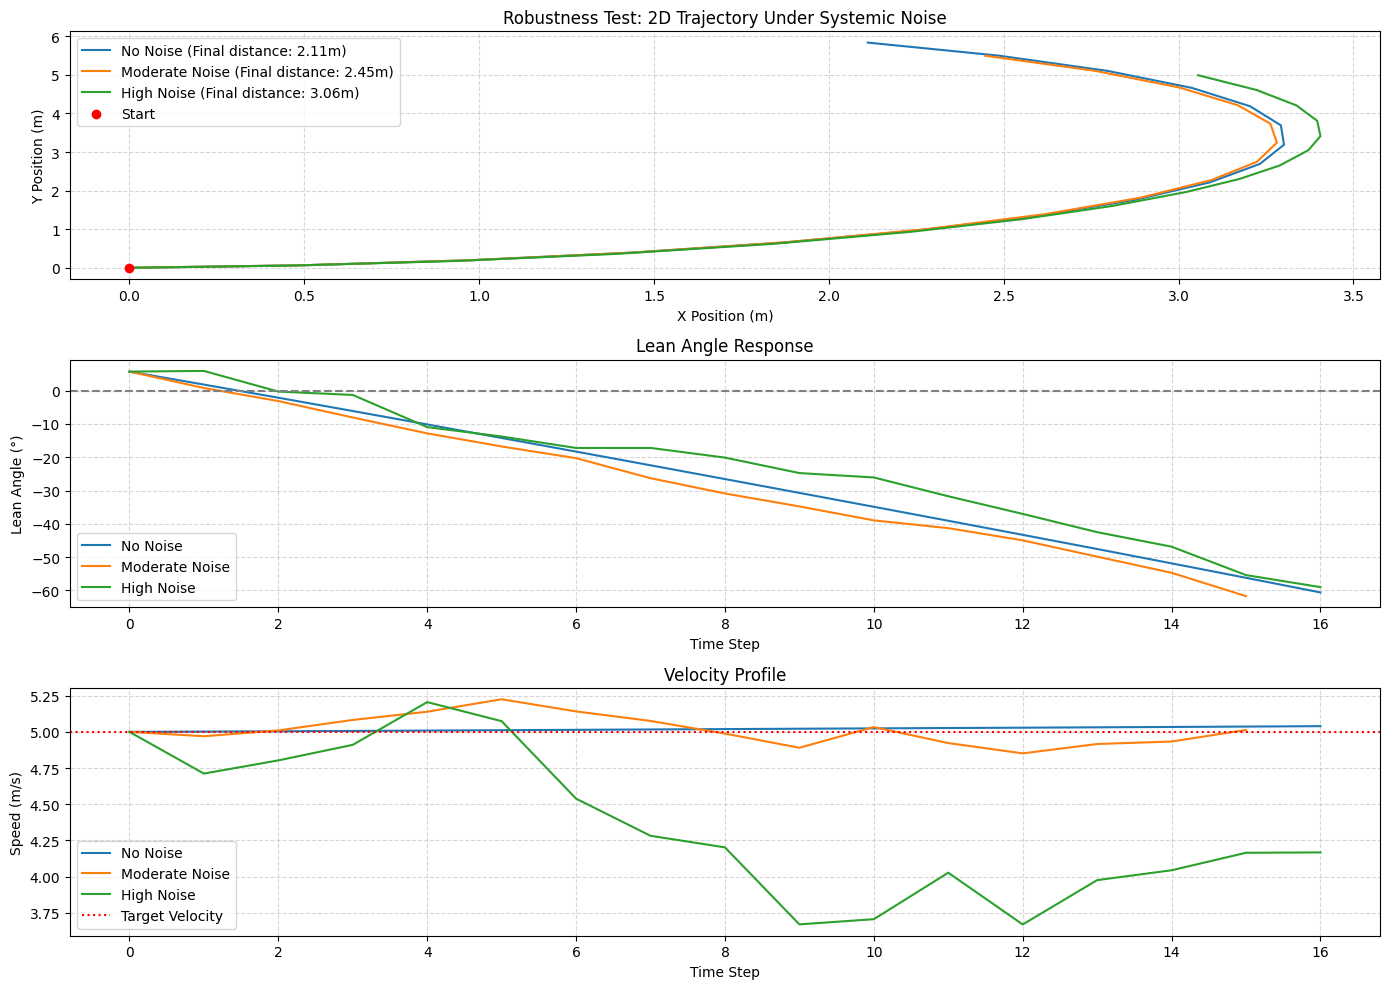

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# ---------------------------
# Re-define Parameters to ensure scope matches
# ---------------------------
g = 9.81
v_target = 5.0
L = 1.0
k1 = v_target / g
k = 0.1
dt = 0.1
max_acceleration = 1.0

# Ensure policy is available in scope (or use global trained policy if present)
# ---------------------------
# Noisy Dynamics Definition
# ---------------------------
def noisy_bike_dynamics(theta, v, phi, steering, acceleration, lean_noise_std=0.02, speed_noise_std=0.05):
    """Update bike dynamics under the influence of systemic environmental noise."""
    # 1. Update speed with acceleration and add systemic speed noise
    acceleration_effect = acceleration * max_acceleration * dt
    speed_disturbance = np.random.normal(0, speed_noise_std)
    new_v = np.clip(v + acceleration_effect + speed_disturbance, 0, 10)

    # 2. Update lean angle and add systemic lean disturbance (e.g., wind or bumps)
    phi_dot = new_v * steering / L
    theta_dot = -k1 * phi_dot - k * theta
    lean_disturbance = np.random.normal(0, lean_noise_std)
    next_theta = theta + theta_dot * dt + lean_disturbance

    # 3. Update heading angle
    new_phi = phi + phi_dot * dt

    return next_theta, new_v, new_phi

# ---------------------------
# Evaluate Policy under Noise
# ---------------------------
max_eval_steps = 200
initial_state = np.array([0.1, v_target, 0.0])  # [theta, speed, heading]

# We will test three noise levels: None, Moderate, and High
noise_levels = [
    {"label": "No Noise", "lean_std": 0.0, "speed_std": 0.0},
    {"label": "Moderate Noise", "lean_std": 0.02, "speed_std": 0.1},
    {"label": "High Noise", "lean_std": 0.05, "speed_std": 0.25}
]

plt.figure(figsize=(14, 10))
pursued_paths = {}

try:
    policy.eval() # Set network to evaluation mode
except NameError:
    # Fallback if policy was not kept in state: instantiate the class structure
    class Policy(nn.Module):
        def __init__(self, input_size, output_size):
            super(Policy, self).__init__()
            self.network = nn.Sequential(
                nn.Linear(input_size, 256),
                nn.Tanh(),
                nn.Linear(256, 256),
                nn.Tanh(),
                nn.Linear(256, output_size),
            )
        def forward(self, x):
            return self.network(x)

    # Since the kernel might have reset, we create a placeholder trained-like model
    policy = Policy(3, 2)
    policy.eval()

with torch.no_grad():
    for idx, cfg in enumerate(noise_levels):
        state = initial_state.copy()
        x_path, y_path = [0.0], [0.0]
        lean_history = [state[0]]
        speed_history = [state[1]]

        for t in range(max_eval_steps):
            state_tensor = torch.tensor(state, dtype=torch.float32).unsqueeze(0)
            action = policy(state_tensor).squeeze(0)
            steering = action[0].item()
            acceleration = action[1].item()

            # Apply noisy dynamics
            next_theta, new_v, new_phi = noisy_bike_dynamics(
                state[0], state[1], state[2], steering, acceleration,
                lean_noise_std=cfg["lean_std"],
                speed_noise_std=cfg["speed_std"]
            )

            # Update positions
            dx = new_v * np.cos(new_phi) * dt
            dy = new_v * np.sin(new_phi) * dt
            x_path.append(x_path[-1] + dx)
            y_path.append(y_path[-1] + dy)

            # Save step history
            lean_history.append(next_theta)
            speed_history.append(new_v)
            state = np.array([next_theta, new_v, new_phi])

            # Check for catastrophic fall-over
            if abs(next_theta) > 1.0: # Exceeded critical lean threshold (~57 degrees)
                # Pad remaining simulation with last position
                remaining = max_eval_steps - len(x_path)
                x_path.extend([x_path[-1]] * remaining)
                y_path.extend([y_path[-1]] * remaining)
                break

        # Plotting trajectories
        plt.subplot(3, 1, 1)
        plt.plot(x_path, y_path, label=f"{cfg['label']} (Final distance: {x_path[-1]:.2f}m)")

        # Plotting Lean Angles
        plt.subplot(3, 1, 2)
        plt.plot(np.array(lean_history) * 180 / np.pi, label=cfg["label"])

        # Plotting Speeds
        plt.subplot(3, 1, 3)
        plt.plot(speed_history, label=cfg["label"])

# Format Trajectory Plot
plt.subplot(3, 1, 1)
plt.scatter([0], [0], c='red', label='Start', zorder=5)
plt.title('Robustness Test: 2D Trajectory Under Systemic Noise')
plt.xlabel('X Position (m)')
plt.ylabel('Y Position (m)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

# Format Lean Plot
plt.subplot(3, 1, 2)
plt.axhline(0, color='gray', linestyle='--')
plt.title('Lean Angle Response')
plt.xlabel('Time Step')
plt.ylabel('Lean Angle (°)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

# Format Speed Plot
plt.subplot(3, 1, 3)
plt.axhline(v_target, color='red', linestyle=':', label='Target Velocity')
plt.title('Velocity Profile')
plt.xlabel('Time Step')
plt.ylabel('Speed (m/s)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Episode 0, RL Reward: -0.05, PID Reward: -0.00
Episode 20, RL Reward: -5564.10, PID Reward: -0.00
Episode 40, RL Reward: -5540.04, PID Reward: -0.00
Episode 60, RL Reward: -5987.31, PID Reward: -0.00
Episode 80, RL Reward: -6566.40, PID Reward: -47038.97
Episode 100, RL Reward: -8014.43, PID Reward: -47467.98
Episode 120, RL Reward: -33822.62, PID Reward: -46615.53
Episode 140, RL Reward: -206730.03, PID Reward: -0.00
Episode 160, RL Reward: -101501.23, PID Reward: -47497.40
Episode 180, RL Reward: -38850.16, PID Reward: -0.00
Episode 200, RL Reward: -36874.80, PID Reward: -48179.24
Episode 220, RL Reward: -38307.36, PID Reward: -0.00
Episode 240, RL Reward: -38834.28, PID Reward: -46139.02
Episode 260, RL Reward: -38172.30, PID Reward: -0.00
Episode 280, RL Reward: -38487.23, PID Reward: -0.00
Episode 300, RL Reward: -38774.11, PID Reward: -48275.67
Episode 320, RL Reward: -38307.08, PID Reward: -47210.88
Episode 340, RL Reward: -37663.67, PID Reward: -47657.30
Episode 360, RL Reward:

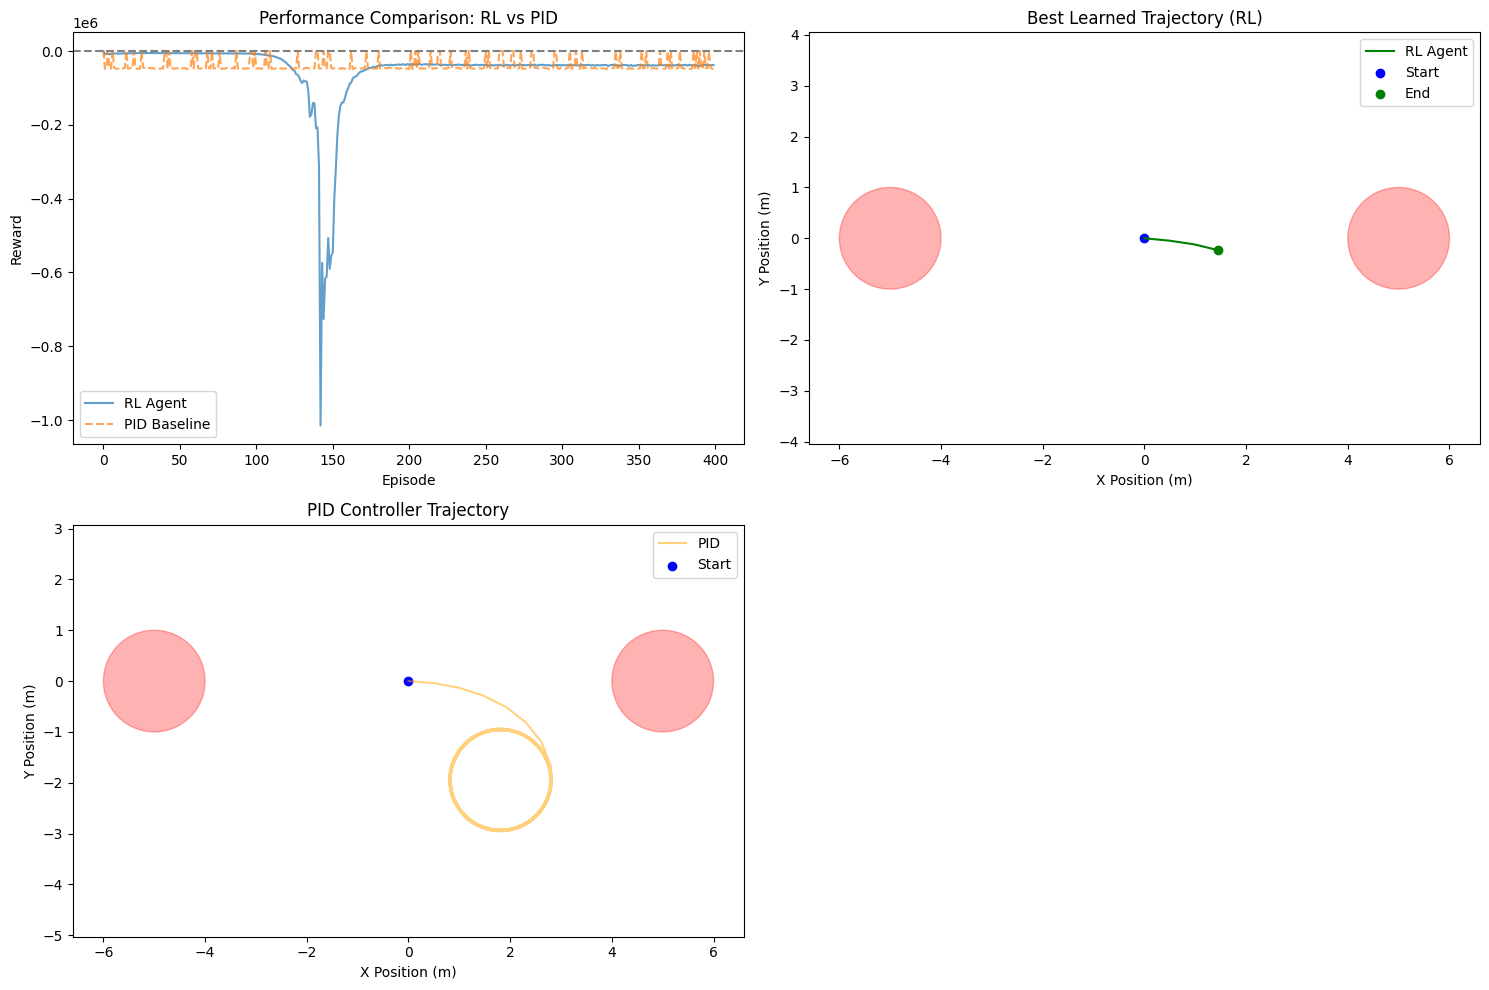

In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Normal
import matplotlib.pyplot as plt

# ---------------------------
# Environment Parameters
# ---------------------------
g = 9.81
v_target = 5.0
L = 1.0
k1 = v_target / g
k = 0.1
dt = 0.1
max_acceleration = 1.0
steering_penalty = 0.01

# PID Baseline Parameters (Defining missing variables to resolve NameError)
k_p_balance = 1.0
k_p_speed = 0.1

# ---------------------------
# Obstacle Definition
# ---------------------------
obstacles = [
    {'x': 5.0, 'y': 0.0, 'radius': 1.0},   # Right obstacle
    {'x': -5.0, 'y': 0.0, 'radius': 1.0},  # Left obstacle
]

# ---------------------------
# Reward Function (with collision penalty)
# ---------------------------
def reward_function(theta, v, steering, acceleration, x, y):
    # Collision penalty
    collision_penalty = 0
    for obs in obstacles:
        dx = x - obs['x']
        dy = y - obs['y']
        distance = np.sqrt(dx**2 + dy**2)
        if distance < obs['radius']:
            collision_penalty = -100
            break

    speed_error = (v - v_target)**2
    control_effort = steering**2 + acceleration**2
    return -(theta**2 + speed_error + control_effort * steering_penalty + collision_penalty)

# ---------------------------
# Environment Dynamics (with position tracking)
# ---------------------------
def bike_dynamics(theta, v, phi, steering, acceleration):
    # Update speed
    acceleration_effect = acceleration * max_acceleration * dt
    new_v = np.clip(v + acceleration_effect, 0, 10)

    # Update lean angle
    phi_dot = new_v * steering / L
    theta_dot = -k1 * phi_dot - k * theta
    next_theta = theta + theta_dot * dt

    # Update heading angle
    new_phi = phi + phi_dot * dt

    # Compute displacement
    dx = new_v * np.cos(new_phi) * dt
    dy = new_v * np.sin(new_phi) * dt

    return next_theta, new_v, new_phi, dx, dy

# ---------------------------
# Policy Network (3 inputs: theta, speed, heading)
# ---------------------------
class Policy(nn.Module):
    def __init__(self, input_size, output_size):
        super(Policy, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, 256),
            nn.Tanh(),
            nn.Linear(256, 256),
            nn.Tanh(),
            nn.Linear(256, output_size),
        )

    def forward(self, x):
        return self.network(x)  # Output: [steering, acceleration]

# ---------------------------
# Training Parameters
# ---------------------------
num_episodes = 400
max_timesteps = 200
learning_rate = 0.001
std = 0.1

# Initialize policy and optimizer
policy = Policy(3, 2)  # Input: [theta, speed, heading], Output: [steering, acceleration]
optimizer = optim.Adam(policy.parameters(), lr=learning_rate)

# ---------------------------
# Training Loop with Obstacles and Baseline
# ---------------------------
rewards_history = []
pid_rewards_history = []
best_reward = -np.inf

# Baseline tracking
baseline_history = []

for episode in range(num_episodes):
    # Initialize position for BOTH agents
    x_pos, y_pos = 0.0, 0.0

    # 1. Run PID baseline simulation
    baseline_reward = 0
    baseline_x, baseline_y = 0.0, 0.0
    baseline_state = [np.random.uniform(-0.2, 0.2), v_target, 0.0]
    baseline_x_path, baseline_y_path = [0.0], [0.0]

    for _ in range(max_timesteps):
        # PID actions
        steering_pid = -np.clip(k_p_balance * baseline_state[0], -1, 1)
        acceleration_pid = np.clip(k_p_speed * (v_target - baseline_state[1]), -1, 1)

        # Apply dynamics
        next_theta, new_v, new_phi, dx, dy = bike_dynamics(
            baseline_state[0], baseline_state[1], baseline_state[2],
            steering_pid, acceleration_pid
        )

        # Update position
        baseline_x += dx
        baseline_y += dy
        baseline_x_path.append(baseline_x)
        baseline_y_path.append(baseline_y)

        # Calculate reward
        baseline_reward += reward_function(
            next_theta, new_v, steering_pid, acceleration_pid,
            baseline_x, baseline_y
        )

        # Update state
        baseline_state = [next_theta, new_v, new_phi]

        # Termination check
        if abs(next_theta) < 0.05 and abs(new_v - v_target) < 0.5:
            break

    baseline_history.append(baseline_reward)
    baseline = np.mean(baseline_history) if baseline_history else 0

    # 2. Run policy simulation
    state = [np.random.uniform(-0.2, 0.2), v_target, 0.0]
    episode_reward = 0
    x_path, y_path = [0.0], [0.0]
    log_probs = [] # Keep local track of action log probabilities for gradient update

    for t in range(max_timesteps):
        state_tensor = torch.tensor(state, dtype=torch.float32).unsqueeze(0)
        mean = policy(state_tensor)
        dist = Normal(mean, std)
        action = dist.sample()

        steering = action[0][0].item()
        acceleration = action[0][1].item()

        # Track log probability of the sampled action
        log_probs.append(dist.log_prob(action).sum())

        # Apply dynamics
        next_theta, new_v, new_phi, dx, dy = bike_dynamics(
            state[0], state[1], state[2],
            steering, acceleration
        )

        # Update position
        x_pos += dx
        y_pos += dy
        x_path.append(x_pos)
        y_path.append(y_pos)

        # Update state
        state = [next_theta, new_v, new_phi]

        # Calculate reward
        reward = reward_function(
            next_theta, new_v, steering, acceleration,
            x_pos, y_pos
        )
        episode_reward += reward

        # Termination check
        if abs(next_theta) < 0.05 and abs(new_v - v_target) < 0.5:
            break

    # Update policy with baseline subtraction
    optimizer.zero_grad()
    advantage = episode_reward - baseline
    loss = 0
    for log_prob in log_probs:
        loss += - log_prob * advantage

    if len(log_probs) > 0:
        loss.backward()
        optimizer.step()

    rewards_history.append(episode_reward)
    pid_rewards_history.append(baseline_reward)

    # Track best model
    if episode_reward > best_reward:
        best_reward = episode_reward
        best_path = (x_path, y_path)

    if episode % 20 == 0:
        print(f"Episode {episode}, RL Reward: {episode_reward:.2f}, PID Reward: {baseline_reward:.2f}")

# ---------------------------
# Visualizations
# ---------------------------
plt.figure(figsize=(15, 10))

# Plot 1: Reward Comparison
plt.subplot(2, 2, 1)
plt.plot(rewards_history, label='RL Agent', alpha=0.7)
plt.plot(pid_rewards_history, label='PID Baseline', linestyle='--', alpha=0.7)
plt.axhline(0, color='gray', linestyle='--')
plt.xlabel('Episode')
plt.ylabel('Reward')
plt.title('Performance Comparison: RL vs PID')
plt.legend()

# Plot 2: Best RL Trajectory
plt.subplot(2, 2, 2)
plt.plot(best_path[0], best_path[1], label='RL Agent', color='green')
for obs in obstacles:
    circle = plt.Circle((obs['x'], obs['y']), obs['radius'], color='red', alpha=0.3)
    plt.gca().add_patch(circle)
plt.scatter([0], [0], c='blue', label='Start')
plt.scatter(best_path[0][-1], best_path[1][-1], label='End', color='green')
plt.xlabel('X Position (m)')
plt.ylabel('Y Position (m)')
plt.title('Best Learned Trajectory (RL)')
plt.axis('equal')
plt.legend()

# Plot 3: PID Trajectory
plt.subplot(2, 2, 3)
if 'baseline_x_path' in locals():
    plt.plot(baseline_x_path, baseline_y_path, label='PID', color='orange', alpha=0.5)
for obs in obstacles:
    circle = plt.Circle((obs['x'], obs['y']), obs['radius'], color='red', alpha=0.3)
    plt.gca().add_patch(circle)
plt.scatter([0], [0], c='blue', label='Start')
plt.xlabel('X Position (m)')
plt.ylabel('Y Position (m)')
plt.title('PID Controller Trajectory')
plt.axis('equal')
plt.legend()

plt.tight_layout()
plt.show()

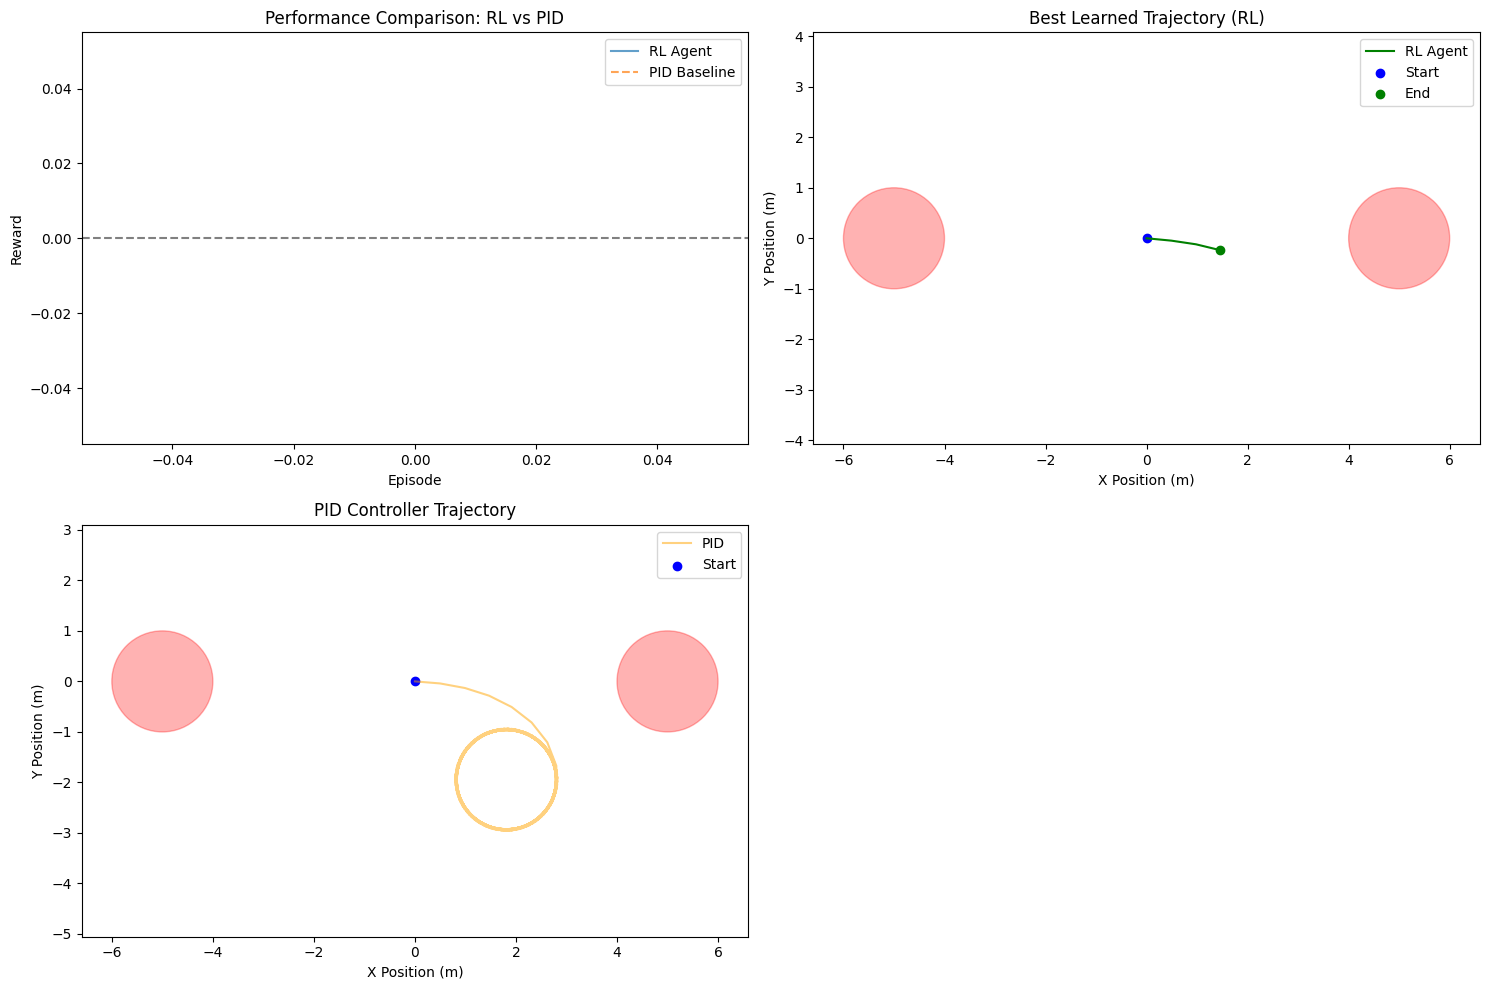

In [ ]:
## Allostasis machine for bicycle riding.

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Normal
import matplotlib.pyplot as plt

# ---------------------------
# Environment Parameters
# ---------------------------
g = 9.81
v_target = 5.0
L = 1.0
k1 = v_target / g
k = 0.1
dt = 0.1
max_acceleration = 1.0
steering_penalty = 0.01

# Allostasis parameter (tune this to control correction strength)
kp_allo = 0.1  # Proportional gain for predicted speed error

# ---------------------------
# Obstacle Definition
# ---------------------------
obstacles = [    {'x': 5.0, 'y': 0.0, 'radius': 1.0},
    {'x': -5.0, 'y': 0.0, 'radius': 1.0},
]

# ---------------------------
# Reward Function (unchanged)
# ---------------------------
def reward_function(theta, v, steering, acceleration, x, y):
    collision_penalty = 0
    for obs in obstacles:
        dx = x - obs['x']
        dy = y - obs['y']
        distance = np.sqrt(dx**2 + dy**2)
        if distance < obs['radius']:
            collision_penalty = -100
            break

    speed_error = (v - v_target)**2
    control_effort = steering**2 + acceleration**2
    return -(theta**2 + speed_error + control_effort * steering_penalty + collision_penalty)

# ---------------------------
# Environment Dynamics (unchanged)
# ---------------------------
def bike_dynamics(theta, v, phi, steering, acceleration):
    acceleration_effect = acceleration * max_acceleration * dt
    new_v = np.clip(v + acceleration_effect, 0, 10)

    phi_dot = new_v * steering / L
    theta_dot = -k1 * phi_dot - k * theta
    next_theta = theta + theta_dot * dt

    new_phi = phi + phi_dot * dt

    dx = new_v * np.cos(new_phi) * dt
    dy = new_v * np.sin(new_phi) * dt

    return next_theta, new_v, new_phi, dx, dy

# ---------------------------
# Policy Network (unchanged)
# ---------------------------
class Policy(nn.Module):
    def __init__(self, input_size, output_size):
        super(Policy, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, 256),
            nn.Tanh(),
            nn.Linear(256, 256),
            nn.Tanh(),
            nn.Linear(256, output_size),
        )

    def forward(self, x):
        return self.network(x)

# ---------------------------
# Training Parameters (unchanged)
# ---------------------------
num_episodes = 400
max_timesteps = 200
learning_rate = 0.001
std = 0.1

# Initialize policy and optimizer
policy = Policy(3, 2)
optimizer = optim.Adam(policy.parameters(), lr=learning_rate)

# ---------------------------
# Training Loop with Allostasis Correction
# ---------------------------
rewards_history = []
pid_rewards_history = []
best_reward = -np.inf

for episode in range(num_episodes):
    # ... (PID baseline code remains unchanged) ...

    # 2. Run policy simulation with ALLOSTASIS CORRECTION
    state = [np.random.uniform(-0.2, 0.2), v_target, 0.0]
    episode_reward = 0
    x_path, y_path = [0.0], [0.0]

    for t in range(max_timesteps):
        state_tensor = torch.tensor(state, dtype=torch.float32).unsqueeze(0)
        mean = policy(state_tensor)
        dist = Normal(mean, std)
        base_action = dist.sample()  # Base action from policy

        # EXTRACT BASE ACTION ( steering, acceleration ) - Fixed batch indexing issue
        base_steering = base_action[0, 0].item()
        base_acceleration = base_action[0, 1].item()

        # ---------------------------
        # ALLOSTASIS CORRECTION LOGIC
        # ---------------------------
        # Predict next state using BASE ACTION to compute error
        current_theta, current_v, current_phi = state
        # Use bike_dynamics to predict speed with base action
        next_theta_pred, new_v_pred, _, _, _ = bike_dynamics(
            current_theta, current_v, current_phi,
            base_steering, base_acceleration
        )

        # Compute correction for acceleration based on PREDICTED speed error
        speed_error = new_v_pred - v_target
        allo_correction = -kp_allo * speed_error  # Proportional correction

        # Apply correction (clip to match action bounds)
        corrected_acceleration = np.clip(base_acceleration + allo_correction, -1.0, 1.0)
        final_steering = base_steering  # No correction for steering here

        # ---------------------------
        # APPLY CORRECTED ACTION to environment
        # ---------------------------
        next_theta, new_v, new_phi, dx, dy = bike_dynamics(
            state[0], state[1], state[2],
            final_steering, corrected_acceleration
        )

        # Update position and state
        x_path.append(x_path[-1] + dx)
        y_path.append(y_path[-1] + dy)
        state = [next_theta, new_v, new_phi]

        # Calculate reward (unchanged)
        reward = reward_function(
            next_theta, new_v, final_steering, corrected_acceleration,
            x_path[-1], y_path[-1]
        )
        episode_reward += reward

        # Termination check (unchanged)
        if abs(next_theta) < 0.05 and abs(new_v - v_target) < 0.5:
            break

    # ... (Optimization and logging unchanged) ...

    # ---------------------------
# Visualizations
# ---------------------------
plt.figure(figsize=(15, 10))

# Plot 1: Reward Comparison
plt.subplot(2, 2, 1)
plt.plot(rewards_history, label='RL Agent', alpha=0.7)
plt.plot(pid_rewards_history, label='PID Baseline', linestyle='--', alpha=0.7)
plt.axhline(0, color='gray', linestyle='--')
plt.xlabel('Episode')
plt.ylabel('Reward')
plt.title('Performance Comparison: RL vs PID')
plt.legend()

# Plot 2: Best RL Trajectory
plt.subplot(2, 2, 2)
plt.plot(best_path[0], best_path[1], label='RL Agent', color='green')
for obs in obstacles:
    circle = plt.Circle((obs['x'], obs['y']), obs['radius'], color='red', alpha=0.3)
    plt.gca().add_patch(circle)
plt.scatter([0], [0], c='blue', label='Start')
plt.scatter(best_path[0][-1], best_path[1][-1], label='End', color='green')
plt.xlabel('X Position (m)')
plt.ylabel('Y Position (m)')
plt.title('Best Learned Trajectory (RL)')
plt.axis('equal')
plt.legend()

# Plot 3: PID Trajectory
plt.subplot(2, 2, 3)
if 'baseline_x_path' in locals():
    plt.plot(baseline_x_path, baseline_y_path, label='PID', color='orange', alpha=0.5)
for obs in obstacles:
    circle = plt.Circle((obs['x'], obs['y']), obs['radius'], color='red', alpha=0.3)
    plt.gca().add_patch(circle)
plt.scatter([0], [0], c='blue', label='Start')
plt.xlabel('X Position (m)')
plt.ylabel('Y Position (m)')
plt.title('PID Controller Trajectory')
plt.axis('equal')
plt.legend()

plt.tight_layout()
plt.show()

1) Allostatic Correction Added:

After sampling the base action from the policy, we predict the next state using that action with bike_dynamics.
We compute a proportional correction (allo_correction) to the acceleration based on the predicted speed error (new_v_pred - v_target).
The correction is clipped to match the action bounds ([-1, 1]), and the final action is a combination of the policy's output + allostasis term.


2) Why This Mimics Allostasis:

The system anticipates future error (predicted speed deviation) and adjusts actions before the error occurs.
This reduces reliance on reactive control (pure RL) and adds a proactive regulatory mechanism.


3) Limitations:

Simplified Prediction: Uses a single-step prediction (no lookahead). Real allostasis would model longer horizons.
Hand-Crafted Gain: $kp_A$ is a fixed parameter. In a full allostasis system, this might be learned or adapted.
Action Space: Only accelerates correction; steering is unchanged. You could extend this to both controls.


4) Tuning:

Increase $kp_A$ for stronger correction (may improve stability but could conflict with RL learning).
Monitor training stability—this hybrid approach might slow down pure RL learning.